In [6]:
import sys
sys.path.append('../lib')

import numpy as np
import glob
import os
import copy
import scipy.linalg as sp
import matplotlib as mpl
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn import mixture
from gmr import *
from plot_utils import *
from IPython.display import clear_output

In [7]:
n_dim = 2  # problem in 2D, no derivatives

In [8]:
from scipy.io import loadmat # loading data from matlab
letter = 'A' # choose a letter in the alphabet
letter_data = loadmat('../data/2Dletters/' + '%s.mat' % letter)

demos = [d['pos'][0][0].T for d in letter_data['demos'][0]] # list of arrays
n_demos = len(demos)

# Add time column
for i in range(0,n_demos):
    time = np.linspace(0,1,demos[i].shape[0])
    demos[i] = np.c_[time,demos[i]]

# Concatenate
data = np.array(demos)
data = data.reshape(-1,3)

In [9]:
KGMM = 8 # GMM states
N = 100 # sampled points
l = 0.125 # kernel scale
h = 1.0 # kernel noise variance
lambda_1 = 0.10260934359184139 # KMP hyperparameters
# lambda_2 = 1E-2
lambda_2 = lambda_1
alpha = 77.14113663445808

In [10]:
# Train GMM on demonstration data
gmm = mixture.GaussianMixture(n_components=KGMM,covariance_type='full',reg_covar=1E-5,init_params='kmeans')
gmm.fit(data)

GaussianMixture(n_components=8, reg_covar=1e-05)

In [11]:
# GMR
d_in = range(0,1)
d_out = range(1,3)
x_in = np.linspace(0,1,N)
mu, sigma = gmr(gmm, x_in, d_in, d_out, N)

In [12]:
# Blockize GMM output
mu_block = mu.reshape(-1,1)                         # mean
pntr_sigma = []                  
for i in range(0,sigma.shape[0]):                   # covariance
    pntr_sigma.append(sigma[i,:,:])
sigma_block = sp.block_diag(*pntr_sigma)

In [13]:
def rbf_kernel(x_i,x_j,l=0.1,h=1.0):
    dif = x_i-x_j
    sq_dist = np.dot(dif,dif)
#     k = h*np.exp(-l*dist)
    k = h*np.exp(-sq_dist/(2*l**2))
    return k

In [14]:
def kernel_matrix(x1,x2,l,h):
    K = np.zeros((x1.shape[0],x2.shape[0]))
    for i in range(0,x1.shape[0]):
        for j in range(0,x2.shape[0]):
            K[i,j] = rbf_kernel(x1[i,:],x2[j,:],l,h)
    return K

In [15]:
# Compute K
nb_dim_in = 1
nb_dim_out = 2
x_in = x_in.reshape(-1,nb_dim_in)

x_test = x_in #

In [16]:
K = np.kron(kernel_matrix(x_in,x_in,l,h), np.eye(nb_dim_out,nb_dim_out)) # K
K_s = np.kron(kernel_matrix(x_test,x_in,l,h), np.eye(nb_dim_out,nb_dim_out)) # k*
K_ss = np.kron(kernel_matrix(x_test,x_test,l,h), np.eye(nb_dim_out,nb_dim_out)) # k**

## Prediction
Psi = K_s@(np.linalg.inv(K + lambda_1*sigma_block))
mu_out = Psi@mu_block # prediction mean
traj_mean = mu_out
mu_out = mu_out.reshape(-1,nb_dim_out)
Sigma_out = alpha*(K_ss - K_s@(np.linalg.inv(K + lambda_2*sigma_block))@K_s.T) # prediciton covariance
traj_cov = Sigma_out

In [17]:
x_orig = np.copy(x_in)
sigma_block_orig = np.copy(sigma_block)
mu_block_orig = np.copy(mu_block)
pntr_sigma_orig = copy.deepcopy(pntr_sigma)

In [19]:
import time
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

/home/robot-learn/miniforge3/envs/robodiff/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [20]:
via_point1 = np.array([-9.67309744, -7.60580044])
via_point2 = np.array([1.93715746,  -3.47546397])
via_point3 = np.array([5.97952464, -1.44903256])

via_time1 = 0.0
via_time2 = 0.465
via_time3 = 1.0
idx1 = np.argmin(np.abs(x_in[:,0]-via_time1))
idx2 = np.argmin(np.abs(x_in[:,0]-via_time2))
idx3 = np.argmin(np.abs(x_in[:,0]-via_time3))


# Compute K, invK, and other auxiliary parameters
I = np.eye(nb_dim_out,nb_dim_out)
K = np.kron(kernel_matrix(x_in,x_in,l,h), I) # initialize K
inv_K_Sigma = np.linalg.inv(K + lambda_1*sigma_block)

K_s = np.kron(kernel_matrix(x_test, x_in, l, h), I) # k*
Psi = K_s @ inv_K_Sigma
Psi_mu_block = Psi @ mu_block

In [21]:
def objective_nskmp(trial):
    
    # Sample input and candidate via-points
    max_q = 500
    via_in1 = trial.suggest_float('via_in1', 0.0, 1.0, log=False)
    via_out1_x = trial.suggest_float('via_out1_x', -max_q, max_q, log=False)
    via_out1_y = trial.suggest_float('via_out1_y', -max_q, max_q, log=False)

    via_in2 = trial.suggest_float('via_in2', 0.0, 1.0, log=False)
    via_out2_x = trial.suggest_float('via_out2_x', -max_q, max_q, log=False)
    via_out2_y = trial.suggest_float('via_out2_y', -max_q, max_q, log=False)

    # Define input and exploration command for the sampled parameters
    t_ = np.array([via_in1, via_in2])
    t_ = t_.reshape(-1,1)
    q = np.zeros((nb_dim_out*2,1))
    q[0,0] = via_out1_x
    q[1,0] = via_out1_y
    q[2,0] = via_out2_x
    q[3,0] = via_out2_y    
    
    # Compute kernel matrices required for null space approach K_s_, K_
    K_s_ = np.kron(kernel_matrix(x_test, t_, l, h), np.eye(nb_dim_out, nb_dim_out))
    K_  = np.kron(kernel_matrix(x_in, t_, l, h), np.eye(nb_dim_out, nb_dim_out))

    # Compute the prediction
    pred = Psi_mu_block + (K_s_- Psi @ K_) @ q
    pred = pred.reshape(-1,nb_dim_out)


    # compute distance between prediction in idx and via-point
    cost_obs = 0

    dis1 = np.linalg.norm(pred[idx1,:] - via_point1)
    dis2 = np.linalg.norm(pred[idx2,:] - via_point2)
    dis3 = np.linalg.norm(pred[idx3,:] - via_point3)
    
    cost_obs += 100*dis1
    cost_obs += 100*dis2
    cost_obs += 100*dis3

    # if dis1 > 1.0:
    #     cost_obs += 10*dis1
    
    # if dis2 > 1.0:
    #     cost_obs += 10*dis2
    
    # if dis3 > 1.0:
    #     cost_obs += 10*dis3

    # add smoothness cost
    cost_obs += 1 * np.linalg.norm(np.diff(pred, axis=0), axis=1).sum()

    return cost_obs

Optimization time: 0.27765 seconds
Best value: 391.51282517464836
Best params: {'via_in1': 0.4666259712067456, 'via_out1_x': -319.7408684349537, 'via_out1_y': 239.17453169823645, 'via_in2': 0.42289571785776114, 'via_out2_x': -349.86901297244844, 'via_out2_y': -262.1850431989089}


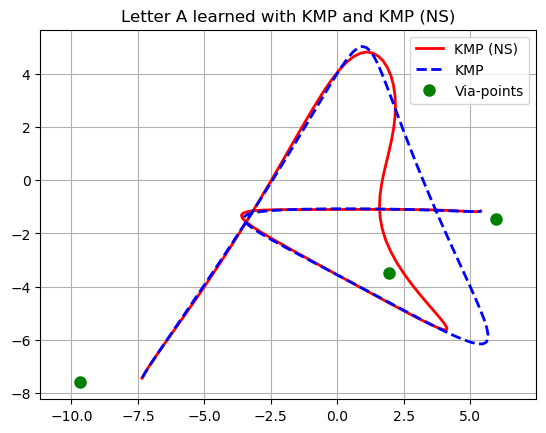

{'via_in1': 0.9448419302134219,
 'via_out1_x': 46.45158764919776,
 'via_out1_y': 415.5552534329055,
 'via_in2': 0.44505775412533827,
 'via_out2_x': -479.05577461693656,
 'via_out2_y': -7.580268580194492}

In [ ]:

# --- Run Optuna once per scenario (don’t recreate the study in a tight while-loop) ---
sampler = optuna.samplers.TPESampler(seed=42, n_startup_trials=20)
pruner  = optuna.pruners.MedianPruner(n_warmup_steps=50)

start_time = time.time()
# study = optuna.create_study(direction='minimize', sampler=sampler, pruner=pruner)
study = optuna.create_study(direction='minimize')
study.optimize(objective_nskmp, n_trials=50, timeout=30)
end_time = time.time()
print("Optimization time: %.5f seconds" % (end_time - start_time))

print("Best value:", study.best_value)
print("Best params:", study.best_params)

# Use best params to reconstruct pred
best = study.best_params
t_sorted = np.array([best['via_in1'], best['via_in2']]).reshape(-1,1)
q = np.array([[best['via_out1_x']], [best['via_out1_y']], [best['via_out2_x']], [best['via_out2_y']]])

I_out = np.eye(nb_dim_out)
K_s_ = np.kron(kernel_matrix(x_test, t_sorted, l, h), I_out)
K_   = np.kron(kernel_matrix(x_in,   t_sorted, l, h), I_out)
pred = Psi_mu_block + (K_s_ - Psi @ K_) @ q
best_traj = pred.reshape(-1, nb_dim_out)
np.save("NS_KMP_A", best_traj)


plt.plot(best_traj[:,0], best_traj[:,1], 'r-', lw=2, label='KMP (NS)')
plt.plot(mu_out[:,0], mu_out[:,1], 'b--', lw=2, label='KMP')

plt.plot(via_point1[0], via_point1[1], 'go', markersize=8, label='Via-points')
plt.plot(via_point2[0], via_point2[1], 'go', markersize=8)
plt.plot(via_point3[0], via_point3[1], 'go', markersize=8)
plt.title('Letter %s learned with KMP and KMP (NS)' % letter)
plt.axis('equal')
plt.legend()
plt.grid()
plt.show()
# plt.savefig('figures/NS_KMP_%s.png' % letter, dpi=300)
{'via_in1': 0.9448419302134219, 'via_out1_x': 46.45158764919776, 'via_out1_y': 415.5552534329055, 
 'via_in2': 0.44505775412533827, 'via_out2_x': -479.05577461693656, 'via_out2_y': -7.580268580194492}

